
## Cell 1 — Imports and Dataset Configuration

**Purpose:** Initialize the Python environment and define the locations of the MRI dataset, preprocessing directory, and output files.

### Description

This cell imports the necessary Python libraries, including:

- **NumPy:** Numerical operations and array manipulation.
- **Pandas:** Dataset organization and tabular data processing.
- **Pillow (PIL):** Loading and manipulating MRI images.
- **Matplotlib:** Visualization of MRI images and preprocessing results.
- **scikit-image:** Image resizing, normalization, and contrast enhancement.

The cell also establishes the project directory, locates the **Brain Tumor 12K MRI dataset**, sets a reproducibility seed (`SEED = 42`), and specifies a standard image resolution of **224 × 224 pixels**.

### Why It Matters

Centralizing dataset paths and configuration settings makes the preprocessing pipeline easier to maintain, reproduce, and reuse across all **eight individual models and the final ninth hybrid model**.


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from skimage.transform import resize
from skimage import exposure

SEED = 42
np.random.seed(SEED)

# Find repository root from the notebook's working directory
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "Datasets" / "Brain Tumor 12K Mri Images" / "DATA.json").exists()
)

DATA_ROOT = PROJECT_ROOT / "Datasets" / "Brain Tumor 12K Mri Images"
IMAGE_ROOT = DATA_ROOT / "Images_" / "Images_"

PREPROCESS_DIR = PROJECT_ROOT / "Code" / "preprocessing"
MANIFEST_DIR = PREPROCESS_DIR / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)

print("Project root:", PROJECT_ROOT)
print("Dataset found:", DATA_ROOT.exists())
print("Image root found:", IMAGE_ROOT.exists())

Project root: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research
Dataset found: True
Image root found: True



## Cell 2 — Dataset Metadata Extraction and Master Manifest Generation

**Purpose:** Extract, organize, and validate metadata associated with the MRI images in the Brain Tumor 12K dataset, creating a standardized master manifest for all subsequent machine learning experiments.

### Description

This cell reads the dataset's `DATA.json` metadata file and constructs a structured Pandas DataFrame containing information about each MRI image, including:

- **Image Path:** The absolute filesystem location of each original MRI image.
- **Classification Label:** A binary label indicating whether a tumor or lesion is annotated as present (`1`) or absent (`0`).
- **Tumor Type:** The specific tumor classification, such as glioblastoma, meningioma, astrocytoma, or medulloblastoma.
- **MRI Sequence:** The imaging sequence or modality, such as T1-weighted, T1 contrast-enhanced (T1C+), or T2-weighted MRI.
- **Patient ID:** A patient identifier, if available in the dataset metadata.
- **Segmentation Mask Path:** A reference to the corresponding tumor segmentation mask, when provided.
- **Bounding Box Path:** A reference to the corresponding tumor bounding-box annotation, when provided.
- **Image Dimensions:** The original width and height of each MRI image.

The cell verifies that the original MRI image files exist, excludes records with missing or invalid binary labels, and checks for duplicate image paths.

Finally, it exports the organized dataset information into a CSV file named `brain_mri_master_manifest.csv`.

### Why It Matters

Creating a centralized master manifest ensures that all eight individual models and the final ninth hybrid model use a consistent dataset inventory and classification labels.

It also provides a foundation for dataset quality control, reproducible train/validation/test partitioning, tumor classification, segmentation, object detection, and comparative model evaluation.

The master manifest does not itself establish patient-level independence; this must be addressed separately when defining the dataset splits.


In [3]:
with open(DATA_ROOT / "DATA.json", "r", encoding="utf-8") as f:
    metadata = json.load(f)

records = []

for relative_path, info in metadata.items():

    image_path = IMAGE_ROOT / Path(relative_path)

    if not image_path.is_file():
        continue

    label = info.get("has_lesion")

    if label not in (0, 1, False, True):
        continue

    records.append({
        "image_path": str(image_path.resolve()),
        "label": int(label),
        "tumor_type": info.get("tumor_type"),
        "sequence": info.get("sequence"),
        "patient_id": info.get("patient_id"),
        "mask_path": info.get("mask_path"),
        "bbox_path": info.get("bbox_path"),
        "original_width": info.get("width"),
        "original_height": info.get("height")
    })

df = pd.DataFrame(records)

assert not df.empty, "No valid MRI images found."
assert df["image_path"].is_unique, "Duplicate image paths detected."

MANIFEST_PATH = MANIFEST_DIR / "brain_mri_master_manifest.csv"
df.to_csv(MANIFEST_PATH, index=False)

print("Total MRI images:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nMRI sequences:")
print(df["sequence"].value_counts())

print("\nSaved manifest:", MANIFEST_PATH)

Total MRI images: 11520

Class distribution:
label
1    10323
0     1197
Name: count, dtype: int64

MRI sequences:
sequence
T1C+    4642
T1      3799
T2      3079
Name: count, dtype: int64

Saved manifest: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\preprocessing\manifests\brain_mri_master_manifest.csv



## Cell 3 — Standardized MRI Image Preprocessing

**Purpose:** Define a reusable MRI image preprocessing function that standardizes image dimensions, grayscale intensity values, and optional contrast enhancement before feature extraction or model training.

### Description

This cell defines the `preprocess_mri()` function, which applies a sequence of image preprocessing operations:

1. **Image Loading:** Opens an MRI image using Pillow (PIL) and converts it into a NumPy array.

2. **Grayscale Conversion:** Converts the MRI image into a single-channel grayscale representation, reducing the input to intensity information.

3. **Image Resizing:** Resizes the MRI image to a standardized resolution of **224 × 224 pixels**, ensuring consistent input dimensions.

4. **Robust Intensity Normalization:** Calculates the 1st and 99th percentile intensity values, clips extreme values, and rescales pixel intensities into the range `[0, 1]`.

5. **Intensity Clipping:** Explicitly constrains the normalized image values to `[0, 1]`, ensuring compatibility with subsequent image processing operations.

6. **Optional CLAHE Enhancement:** Applies Contrast Limited Adaptive Histogram Equalization (CLAHE) when `use_clahe=True`, improving local image contrast while limiting excessive amplification.

7. **Data Type Conversion:** Returns the preprocessed MRI image as a 32-bit floating-point (`float32`) NumPy array.

The function accepts configurable parameters, including `image_path`, `image_size`, and `use_clahe`, allowing the preprocessing pipeline to be adapted to different experimental requirements.

### Why It Matters

Standardized MRI preprocessing helps reduce inconsistencies in image dimensions, numerical intensity scales, and input formatting across the dataset.

This provides a common preprocessing foundation for classical computer vision, machine learning, deep learning, and hybrid modeling approaches.

The optional CLAHE parameter also supports controlled experiments comparing normalized MRI images with contrast-enhanced images.

Although this function provides a shared baseline, individual architectures may require additional preprocessing, including RGB conversion, specialized normalization, augmentation, or preservation of spatial relationships between MRI images and segmentation annotations.


In [6]:
def preprocess_mri(
    image_path,
    image_size=(224, 224),
    use_clahe=False
):
    """
    Standardized MRI preprocessing.

    1. Load grayscale MRI
    2. Resize image
    3. Normalize intensity to [0, 1]
    4. Optionally apply CLAHE

    Returns:
        Float32 image with values in [0, 1].
    """

    # Load grayscale MRI
    with Image.open(image_path) as img:
        image = np.asarray(
            img.convert("L"),
            dtype=np.float32
        )

    # Resize
    image = resize(
        image,
        image_size,
        preserve_range=True,
        anti_aliasing=True
    ).astype(np.float32)

    # Robust percentile normalization
    p1, p99 = np.percentile(image, [1, 99])

    if p99 > p1:
        image = np.clip(image, p1, p99)
        image = (image - p1) / (p99 - p1)
    else:
        image = np.zeros_like(image)

    # Explicitly constrain pixel values
    image = np.clip(image, 0.0, 1.0).astype(np.float32)

    # Optional CLAHE
    if use_clahe:
        image = exposure.equalize_adapthist(
            image,
            clip_limit=0.01
        )

        image = np.clip(image, 0.0, 1.0)

    return image.astype(np.float32)


## Cell 4 — MRI Preprocessing Visualization and Verification

**Purpose:** Visually inspect and verify the results of the standardized MRI preprocessing function by comparing an original MRI image with its normalized and contrast-enhanced versions.

### Description

This cell selects a sample MRI image from the master dataset manifest and generates three visual representations:

1. **Original MRI Image:** Displays the original grayscale MRI image before preprocessing, preserving its original dimensions and intensity representation.

2. **Normalized MRI Image:** Displays the image after resizing to **224 × 224 pixels** and applying robust percentile-based intensity normalization.

3. **CLAHE-Enhanced MRI Image:** Displays the normalized MRI image after applying Contrast Limited Adaptive Histogram Equalization (CLAHE) to enhance local contrast and potentially improve the visibility of anatomical structures.

The three images are displayed side by side using Matplotlib, allowing direct visual comparison of the preprocessing results.

The cell also reports several numerical properties of the original and preprocessed images, including:

- **Original Image Shape:** The dimensions of the MRI image before preprocessing.
- **Preprocessed Image Shape:** The dimensions of the standardized MRI image.
- **Intensity Range:** The minimum and maximum pixel intensity values after normalization.

These outputs help verify that the preprocessing function produces images with the expected dimensions and intensity values.

### Why It Matters

Visual inspection is an important preliminary quality-control step in medical image analysis.

Comparing original, normalized, and CLAHE-enhanced MRI images helps identify potential preprocessing problems, including excessive contrast enhancement, loss of anatomical details, image distortion, and unexpected intensity values.

This verification step also supports decisions about which preprocessing configurations should be evaluated for different computer vision and deep learning models.

The visualization provides an initial qualitative assessment of preprocessing behavior; comprehensive validation across the entire dataset will require additional automated quality-control procedures.


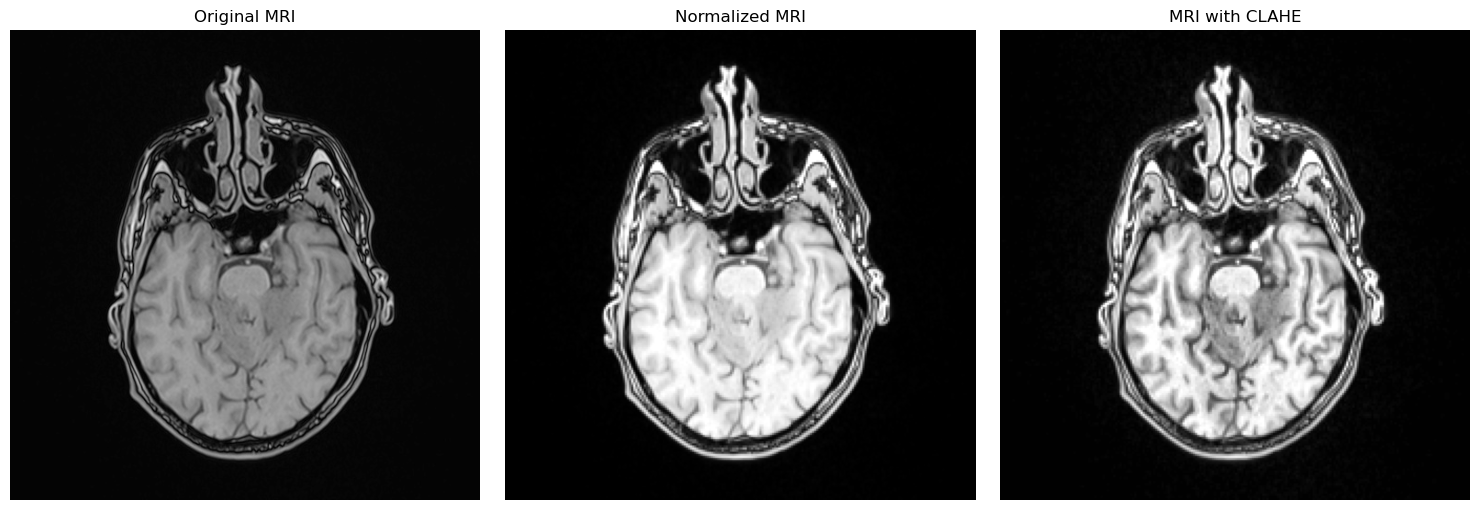

Original shape: (512, 512)
Preprocessed shape: (224, 224)
Intensity range: 0.0 1.0


In [7]:
sample_path = df.iloc[0]["image_path"]

with Image.open(sample_path) as img:
    original = np.asarray(img.convert("L"))

normalized = preprocess_mri(
    sample_path,
    image_size=IMAGE_SIZE,
    use_clahe=False
)

clahe = preprocess_mri(
    sample_path,
    image_size=IMAGE_SIZE,
    use_clahe=True
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original, cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(normalized, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Normalized MRI")

axes[2].imshow(clahe, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("MRI with CLAHE")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original shape:", original.shape)
print("Preprocessed shape:", normalized.shape)
print("Intensity range:", normalized.min(), normalized.max())